# Maidanak Astronomical Observatory GRB database 

First let's install the GRB data from GRBweb

In [2]:
import requests
url = "https://icecube.wisc.edu/~grbweb_public/GRBweb2.sqlite"
r = requests.get(url, allow_redirects=True)
print("Status:", r.status_code)
with open("GRBweb2.sqlite", "wb") as f:
    f.write(r.content)

Status: 200


Check where the data have been installed

In [3]:
import os, subprocess

r = subprocess.run(
    ["find", os.path.expanduser("~"), "-name", "GRBweb2.sqlite", "-type", "f"],
    capture_output=True, text=True
)
print(r.stdout or "Not found anywhere in home directory")

/Users/burkhonabidkhanov/Desktop/gwgrb5/GRBweb2.sqlite
/Users/burkhonabidkhanov/Desktop/Ev/Statistical analysis of the Maidanak GRB database/GRBweb2.sqlite
/Users/burkhonabidkhanov/Library/Mobile Documents/com~apple~CloudDocs/GRBweb2.sqlite
/Users/burkhonabidkhanov/Downloads/GRBweb2.sqlite



Date and time of installation 

In [4]:
import os, datetime

paths = [
    "/Users/burkhonabidkhanov/Desktop/gwgrb5/GRBweb2.sqlite",
    "/Users/burkhonabidkhanov/Desktop/Ev/Statistical analysis of the Maidanak GRB database/GRBweb2.sqlite",
    "/Users/burkhonabidkhanov/Library/Mobile Documents/com~apple~CloudDocs/GRBweb2.sqlite",
    "/Users/burkhonabidkhanov/Downloads/GRBweb2.sqlite",
]

for p in paths:
    if not os.path.exists(p):
        print(f"MISSING: {p}")
        continue
    size_mb = os.path.getsize(p) / 1e6
    mtime = datetime.datetime.fromtimestamp(os.path.getmtime(p))
    print(f"{size_mb:8.1f} MB  |  {mtime:%Y-%m-%d %H:%M}  |  {p}")

    65.3 MB  |  2026-11-02 21:36  |  /Users/burkhonabidkhanov/Desktop/gwgrb5/GRBweb2.sqlite
    62.6 MB  |  2026-09-18 21:37  |  /Users/burkhonabidkhanov/Desktop/Ev/Statistical analysis of the Maidanak GRB database/GRBweb2.sqlite
    62.6 MB  |  2026-08-28 17:32  |  /Users/burkhonabidkhanov/Library/Mobile Documents/com~apple~CloudDocs/GRBweb2.sqlite
    62.6 MB  |  2026-08-28 17:56  |  /Users/burkhonabidkhanov/Downloads/GRBweb2.sqlite


Importing required tools

In [63]:
import numpy as np
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.ticker import AutoMinorLocator
from matplotlib.patches import Patch
from IPython.display import display
from pathlib import Path
import sqlite3

What the data consists of

In [82]:
conn = sqlite3.connect("GRBweb2.sqlite")

n_summary = pd.read_sql_query(
    "SELECT COUNT(*) AS n FROM Summary "
    "WHERE T90 IS NOT NULL AND T90 > 0", conn
)["n"].iloc[0]

det_tables = {
    "BATSE":     ("BATSE",     "GRB_name"),
    "BeppoSAX":  ("BeppoSAX",  "GRB_name"),
    "Swift":     ("Swift",     "GRB_name"),
    "Fermi_GBM": ("Fermi_GBM", "GRB_name_Fermi"),
}

det_rows = {}
for name, (tbl, name_col) in det_tables.items():
    n = pd.read_sql_query(
        f"SELECT COUNT(*) AS n FROM {tbl} "
        f"WHERE T90 IS NOT NULL AND T90 > 0", conn
    )["n"].iloc[0]
    det_rows[name] = n

print("Summary rows (unique GRBs):", n_summary)
print("Sum of per-detector rows:   ",
      sum(det_rows.values()))
print()
for k, v in det_rows.items():
    print(f"  {k:10s}  {v:>6d}")

conn.close()

Summary rows (unique GRBs): 8137
Sum of per-detector rows:    9067

  BATSE         2037
  BeppoSAX      1003
  Swift         1618
  Fermi_GBM     4409


Cheking the files we work to compare with GRBweb

In [66]:
names = [
    "maogrb",
    "mao_grb_list_edited",
    "grb_obs_2026",
    "kuzatuv_stat_2022-2026",
]

for name in names:
    matches = [
        p for p in Path(".").rglob("*")
        if p.is_file() and p.stem == name
    ]
    print(f"\n{name}:")
    for path in matches:
        print(path)
    if not matches:
        print("Not found in the notebook folder or its subfolders")


maogrb:
maogrb.csv

mao_grb_list_edited:
mao_grb_list_edited.csv
mao_grb_list_edited.xlsx

grb_obs_2026:
grb_obs_2026.xlsx

kuzatuv_stat_2022-2026:
kuzatuv_stat_2022-2026.xlsx


Contents of MAO data, we add new 2026 observations into old 

In [67]:
maogrb = pd.read_csv(
    "maogrb.csv", sep=None, engine="python", dtype=str
)
mao_grb_list_edited = pd.read_csv(
    "mao_grb_list_edited.csv", sep=None, engine="python", dtype=str
)

grb_obs_2026 = pd.read_excel(
    "grb_obs_2026.xlsx", sheet_name=None, dtype=str
)
kuzatuv_stat = pd.read_excel(
    "kuzatuv_stat_2022-2026.xlsx", sheet_name=None, dtype=str
)

tables = {
    "maogrb.csv": maogrb,
    "mao_grb_list_edited.csv": mao_grb_list_edited,
}

for sheet, df in grb_obs_2026.items():
    tables[f"grb_obs_2026.xlsx | Sheet: {sheet}"] = df

for sheet, df in kuzatuv_stat.items():
    tables[f"kuzatuv_stat_2022-2026.xlsx | Sheet: {sheet}"] = df

for name, df in tables.items():
    print(f"\n{'=' * 70}\n{name}")
    print(f"Rows: {len(df)} | Columns: {len(df.columns)}")
    print("Column names:", df.columns.tolist())
    display(df.head(10))


maogrb.csv
Rows: 93 | Columns: 17
Column names: ['GRB_name', 'T0', 'date-obs', 'ra', 'dec', 't90', 'filter', 'n_img', 'n_night', 'GRB_trigger_source', 'Unnamed: 10', 'Unnamed: 11', 'Unnamed: 12', 'Unnamed: 13', 'Unnamed: 14', 'Unnamed: 15', 'Unnamed: 16']


,GRB_name,T0,date-obs,ra,dec,t90,filter,n_img,n_night,GRB_trigger_source,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16
0,GRB110210A,9:52:41,NaN,13.0568,7.7797,233,"B, R, V",80,8,Swift/BAT,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,GRB110719A,6:09:11,NaN,24.5808,34.5863,41,"B, I, R, V",118,6,Swift/BAT,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,GRB120803A,7:22:16,NaN,269.531,-6.733,10,R,60,20,Swift/BAT,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,GRB141121A,3:36:13,NaN,122.6693,22.2173,549.9,"I, R",230,16,Swift/BAT,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,GRB151205A,15:46:00,NaN,229.2886,35.744,56.32,R,40,3,Fermi/GBM,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,GRB171010A,19:00:50,NaN,66.74,-10.53,107.266,R,62,4,Fermi/GBM,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,GRB171205A,7:20:43,NaN,167.4146,-12.5885,189.4,"B, I, R, V",454,19,Swift/BAT,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,GRB180418A,6:44:06,NaN,170.1217,24.9331,2.56,R,60,5,Fermi/GBM,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,GRB180514A,13:25:33,NaN,197.3706,36.9724,46.9,R,23,2,Swift/BAT,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,GRB181201A,2:38:00,NaN,319.3208,-12.6333,118.014,"R, V",83,5,Konus-Wind,NaN,NaN,NaN,NaN,NaN,NaN,NaN



mao_grb_list_edited.csv
Rows: 46 | Columns: 14
Column names: ['GRB_name', 'to_time', 'to_mjd', 'date-obs', 'mjd_obs', 'ut_end', 'filter', 'exptime', 'frames', 'date_obs-to', 'Unnamed: 10', 'GRB_name.1', 'date_obs-to.1', 'Season']


,GRB_name,to_time,to_mjd,date-obs,mjd_obs,ut_end,filter,exptime,frames,date_obs-to,Unnamed: 10,GRB_name.1,date_obs-to.1,Season
0,GRB221006A,06/10/2022 00:57,59858.03969,06/10/2022 20:47,59858.86615740741,21:18:09,R,240,8,0.8264699074061355,NaN,GRB221006A,0.8264699074061355,fall
1,GRB221009A,09/10/2022 13:16,59861.553460648145,09/10/2022 15:13,59861.63418981482,15:40:18,R,300,6,0.0807291666715173,NaN,GRB221009A,0.0807291666715173,fall
2,GRB230328B,28/03/2023 14:54,60031.62136574074,23/04/2023 21:22,60057.89041666667,22:56:14,R,300,18,26.26905092592642,NaN,GRB230328B,26.26905092592642,spring
3,GRB230420A,20/04/2023 10:19,60054.429872685185,20/04/2023 18:16,60054.76121527778,19:02:33,R,300,9,0.3313425925953197,NaN,GRB230420A,0.3313425925953197,spring
4,GRB230427A,27/04/2023 10:31,60061.438796296294,27/04/2023 15:49,60061.65930555556,16:50:07,R,300,12,0.2205092592630535,NaN,GRB230427A,0.2205092592630535,spring
5,GRB230506C,06/05/2023 17:09,60070.714733796296,09/05/2023 15:33,60073.648252314815,17:09:16,R,300,18,2.933518518519122,NaN,GRB230506C,2.933518518519122,spring
6,GRB230618A,18/06/2023 03:51,60113.16055555556,18/06/2023 17:07,60113.71337962963,17:55:04,R,300,10,0.5528240740750334,NaN,GRB230618A,0.5528240740750334,summer
7,GRB230728A,28/07/2023 02:49,60153.11803240741,28/07/2023 22:12,60153.925,23:24:10,R,300,15,0.8069675925944466,NaN,GRB230728A,0.8069675925944466,summer
8,GRB230812B,12/08/2023 18:58,60168.79041666666,13/08/2023 18:02,60169.751655092594,18:48:45,B,300,10,0.9612384259307872,NaN,GRB230812B,0.9612384259307872,summer
9,GRB230816A,16/08/2023 16:08,60172.67277777778,17/08/2023 01:15,60173.0522337963,2:01:12,R,300,9,0.3794560185197042,NaN,GRB230816A,0.3794560185197042,summer



grb_obs_2026.xlsx | Sheet: grb_ep_summary_final
Rows: 52 | Columns: 11
Column names: ['Source_Log', 'Filename', 'Object', 'Date1', 'Time1', 'Date2', 'Time2', 'Filter', 'Exp_Time', 'Telescope', 'Img_numbers']


,Source_Log,Filename,Object,Date1,Time1,Date2,Time2,Filter,Exp_Time,Telescope,Img_numbers
0,azt_feb2826.log,feb2826_000006.fits,GRB260226A,2026-02-28 00:00:00,14:53:33,2026-02-28 00:00:00,15:09:46,R,300,1.5m,4
1,azt_mar1326.log,mar1326_000100.fits,GRB260310A,2026-03-13 00:00:00,22:46:03,2026-03-13 00:00:00,23:13:06,R,300,1.5m,6
2,azt_mar1626.log,mar1626_000086.fits,GRB260310A,2026-03-16 00:00:00,22:35:36,2026-03-16 00:00:00,23:02:38,R,300,1.5m,6
3,azt_apr2426.log,apr2426_000110.fits,GRB260310A,2026-04-24 00:00:00,20:46:24,2026-04-24 00:00:00,21:13:26,R,300,1.5m,6
4,azt_apr2626.log,apr2626_000039.fits,GRB260310A,2026-04-26 00:00:00,20:02:46,2026-04-26 00:00:00,20:29:49,R,300,1.5m,6
5,azt_apr2826.log,apr2826_000006.fits,GRB260310A,2026-04-28 00:00:00,19:01:49,2026-04-28 00:00:00,19:31:45,"B,R",300,1.5m,6
6,azt_may1126.log,may1126_000029.fits,GRB260511B,2026-05-11 00:00:00,16:49:08,2026-05-11 00:00:00,17:16:10,R,300,1.5m,6
7,azt_may1226.log,may1226_000006.fits,GRB260511B,2026-05-12 00:00:00,16:34:13,2026-05-12 00:00:00,17:01:15,R,300,1.5m,6
8,azt_may1426.log,may1426_000096.fits,GRB260511B,2026-05-14 00:00:00,19:10:06,2026-05-14 00:00:00,19:37:08,R,300,1.5m,6
9,azt_jun0226.log,jun0226_000053.fits,EP260530a,2026-06-02 00:00:00,17:52:15,2026-06-02 00:00:00,18:19:18,R,300,1.5m,6



kuzatuv_stat_2022-2026.xlsx | Sheet: stat_2022-2025
Rows: 440 | Columns: 8
Column names: ['img_name', 'GRB_name', 'ut-date', 'utstart', 'ut_start_last', 'filter', 'exptime', 'Frames']


,img_name,GRB_name,ut-date,utstart,ut_start_last,filter,exptime,Frames
0,sep0722_000073,GRB220306B,2022-09-07 00:00:00,22:15:58,22:42:59,R,300,6
1,sep0722_000079,GRB220306B,2022-09-07 00:00:00,22:50:07,23:27:57,I,300,8
2,sep0822_000146,GRB220306B,2022-09-08 00:00:00,21:59:52,22:37:51,R,300,8
3,sep0822_000154,GRB220306B,2022-09-08 00:00:00,23:01:47,23:39:38,I,300,8
4,sep0922_000076,GRB220306B,2022-09-09 00:00:00,19:16:28,20:18:08,R,240,15
5,sep0922_000091,GRB220306B,2022-09-09 00:00:00,20:24:54,21:26:35,I,240,15
6,sep1222_000068,GRB220306B,2022-09-12 00:00:00,18:56:31,19:55:59,R,300,11
7,sep1222_000080,GRB220306B,2022-09-12 00:00:00,20:09:52,21:09:21,I,300,11
8,sep1322_000091,GRB220306B,2022-09-13 00:00:00,21:30:02,22:29:31,R,300,12
9,sep1322_000103,GRB220306B,2022-09-13 00:00:00,22:36:31,23:35:59,I,300,12


Here define the targets

In [68]:
obs = grb_obs_2026["grb_ep_summary_final"].copy()
stats = kuzatuv_stat["stat_2022-2025"].copy()

for label, df, date_col in [
    ("grb_obs_2026", obs, "Date1"),
    ("kuzatuv_stat", stats, "ut-date"),
]:
    dates = pd.to_datetime(df[date_col], errors="coerce")
    print(f"\n{label}")
    print("Date range:", dates.min(), "to", dates.max())
    print("Rows by observation year:")
    print(dates.dt.year.value_counts().sort_index().to_string())
    print("Missing/unreadable dates:", dates.isna().sum())

def name_key(series):
    return (
        series.astype("string")
        .str.upper()
        .str.replace(r"\s+", "", regex=True)
    )
    
obs["_name"] = name_key(obs["Object"])
obs["_date"] = pd.to_datetime(obs["Date1"], errors="coerce")
obs_2026 = obs.loc[obs["_date"].dt.year.eq(2026)].copy()

targets = (
    obs_2026.groupby("_name")
    .agg(
        observation_entries=("Object", "size"),
        first_date=("_date", "min"),
        last_date=("_date", "max"),
    )
    .rename_axis("Target")
    .reset_index()
)

targets["in_maogrb"] = targets["Target"].isin(
    name_key(maogrb["GRB_name"])
)
targets["in_followup_list"] = targets["Target"].isin(
    name_key(mao_grb_list_edited["GRB_name"])
)

print("\nTargets observed in 2026:")
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(targets)

catalog = Path("GRBweb2.sqlite")

if catalog.is_file():
    with sqlite3.connect(catalog.resolve().as_uri() + "?mode=ro", uri=True) as conn:
        tables = pd.read_sql_query(
            "SELECT name FROM sqlite_master WHERE type='table' ORDER BY name",
            conn,
        )
        print("\nCatalog tables:", tables["name"].tolist())

        columns = pd.read_sql_query("PRAGMA table_info(Summary)", conn)
        print("\nSummary table columns:")
        print(columns["name"].tolist())
else:
    print("\nGRBweb2.sqlite is not in the notebook's current folder.")


grb_obs_2026
Date range: 2026-02-28 00:00:00 to 2026-09-05 00:00:00
Rows by observation year:
Date1
2026    52
Missing/unreadable dates: 0

kuzatuv_stat
Date range: 2022-09-07 00:00:00 to 2026-08-31 00:00:00
Rows by observation year:
ut-date
2022.0     61
2023.0     79
2024.0     68
2025.0    167
2026.0     49
Missing/unreadable dates: 16

Targets observed in 2026:


,Target,observation_entries,first_date,last_date,in_maogrb,in_followup_list
0,EP260530A,1,2026-06-02,2026-06-02,False,False
1,EP260610B,1,2026-06-10,2026-06-10,False,False
2,EP260623A,2,2026-06-23,2026-06-24,False,False
3,EP260806A,20,2026-08-10,2026-09-05,False,False
4,EP260812A,3,2026-08-12,2026-08-13,False,False
5,GRB260226A,1,2026-02-28,2026-02-28,False,False
6,GRB260310A,5,2026-03-13,2026-04-28,False,False
7,GRB260511B,4,2026-05-11,2026-06-13,False,False
8,GRB260604C,3,2026-06-05,2026-06-07,False,False
9,GRB260610B,4,2026-06-12,2026-06-21,False,False



Catalog tables: ['BATSE', 'BeppoSAX', 'Fermi_GBM', 'Fermi_GBM_precursor_Zhu', 'Fermi_GBM_subthreshold', 'Fermi_LAT', 'GCN_circulars', 'IPN', 'Summary', 'Swift', 'sqlite_sequence']

Summary table columns:
['id', 'GRB_name', 'GRB_name_Fermi', 'T0', 'T0_source', 'ra', 'ra_source', 'decl', 'decl_source', 'pos_error', 'pos_error_source', 'T90', 'T90_source', 'T90_error', 'T90_error_source', 'T90_start', 'T90_start_source', 'fluence', 'fluence_source', 'fluence_error', 'fluence_error_source', 'redshift', 'redshift_source', 'T100', 'GBM_located', 'mjd', 'mjd_source']


Explicitly GRBs

In [69]:
def object_key(series):
    return (
        series.astype("string")
        .str.upper()
        .str.replace(r"\s+", "", regex=True)
        .str.replace(r"^GRB", "", regex=True)
    )

new_grbs = targets.loc[
    targets["Target"].str.fullmatch(r"GRB\d{6}[A-Z]+", na=False),
    ["Target"]
].rename(columns={"Target": "GRB_name"}).copy()

new_grbs["_key"] = object_key(new_grbs["GRB_name"])

with sqlite3.connect(
    Path("GRBweb2.sqlite").resolve().as_uri() + "?mode=ro",
    uri=True
) as conn:
    catalog = pd.read_sql_query("""
        SELECT GRB_name AS catalog_name,
               T0, mjd, T0_source,
               ra, decl, T90, T90_source
        FROM Summary
    """, conn)

catalog["_key"] = object_key(catalog["catalog_name"])

metadata_2026 = new_grbs.merge(catalog, on="_key", how="left")

print("Catalog matches and missing values:")
with pd.option_context("display.max_columns", None, "display.max_rows", None):
    display(metadata_2026.drop(columns="_key"))

print("Multiple catalog rows for the same requested GRB:")
display(
    metadata_2026.loc[
        metadata_2026["GRB_name"].duplicated(keep=False)
    ].drop(columns="_key")
)

Catalog matches and missing values:


,GRB_name,catalog_name,T0,mjd,T0_source,ra,decl,T90,T90_source
0,GRB260226A,GRB260226A,38275.000,61097.442998,"GCN_circulars,Fermi GBM final loc",42.050000,8.033333,173.060,Fermi_GBM
1,GRB260310A,GRB260310A,17830.000,61109.206366,"GCN_circulars,Fermi GBM final loc",219.316667,71.850000,57.344,Fermi_GBM
2,GRB260511B,GRB260511B,39631.000,61171.458692,"GCN_circulars,Fermi GBM final loc",192.606000,4.094000,40.705,Fermi_GBM
3,GRB260604C,GRB260604C,73124.000,61195.846343,"GCN_circulars,Fermi GBM final loc",224.346100,28.655800,6.400,Fermi_GBM
4,GRB260610B,GRB260610B,85573.999,61201.990440,Fermi_GBM,218.158333,27.000000,62.209,Fermi_GBM
5,GRB260802A,GRB260802A,33790.000,61254.391088,"GCN_circulars,SVOM/ECLAIRs Det",339.443100,53.219500,NaN,NaN
6,GRB260808B,GRB260808B,51658.000,61260.597894,"GCN_circulars,SVOM/ECLAIRs Det",345.220200,8.431000,NaN,NaN
7,GRB260809A,GRB260809A,53853.000,61261.623299,"GCN_circulars,SVOM/ECLAIRs Det",356.820000,20.969000,NaN,NaN


Multiple catalog rows for the same requested GRB:


,GRB_name,catalog_name,T0,mjd,T0_source,ra,decl,T90,T90_source


Now for seasonal efficiency statistics

In [70]:
obs_check = grb_obs_2026["grb_ep_summary_final"].copy()
stats_check = kuzatuv_stat["stat_2022-2025"].copy()

obs_check["_date"] = pd.to_datetime(obs_check["Date1"], errors="coerce")
stats_check["_date"] = pd.to_datetime(stats_check["ut-date"], errors="coerce")

def file_key(series):
    return (
        series.astype("string")
        .str.strip()
        .str.lower()
        .str.replace(r"\.(fits?|fts)$", "", regex=True)
    )

obs_check["_object"] = object_key(obs_check["Object"])
stats_check["_object"] = object_key(stats_check["GRB_name"])
obs_check["_file"] = file_key(obs_check["Filename"])
stats_check["_file"] = file_key(stats_check["img_name"])

obs26 = obs_check.loc[obs_check["_date"].dt.year.eq(2026)].copy()
stats26 = stats_check.loc[stats_check["_date"].dt.year.eq(2026)].copy()

keys = ["_object", "_file"]

obs_keys = pd.MultiIndex.from_frame(obs26[keys])
stats_keys = pd.MultiIndex.from_frame(stats26[keys])

def show_records(label, df):
    print(f"\n{label}: {len(df)} rows")
    with pd.option_context("display.max_rows", None, "display.max_columns", None):
        display(df.drop(columns=[
            c for c in df.columns if c.startswith("_")
        ]))

print("Shared target/filename pairs:",
      len(obs_keys.unique().intersection(stats_keys.unique())))

show_records(
    "2026 entries only in grb_obs_2026",
    obs26.loc[~obs_keys.isin(stats_keys)]
)
show_records(
    "2026 entries only in kuzatuv_stat",
    stats26.loc[~stats_keys.isin(obs_keys)]
)

for label, df in [("grb_obs_2026", obs26), ("kuzatuv_stat", stats26)]:
    show_records(
        f"Repeated target/filename pairs in {label}",
        df.loc[df.duplicated(keys, keep=False)]
    )

show_records(
    "Missing or unreadable dates in kuzatuv_stat",
    stats_check.loc[stats_check["_date"].isna()]
)

Shared target/filename pairs: 49

2026 entries only in grb_obs_2026: 3 rows


,Source_Log,Filename,Object,Date1,Time1,Date2,Time2,Filter,Exp_Time,Telescope,Img_numbers
49,azt_sep0126.log,sep0126_000006.fits,EP260806a,2026-09-01 00:00:00,19:14:38,2026-09-01 00:00:00,21:46:14,"B,R,V,I",300,1.5m,26
50,azt_sep0426.log,sep0426_000069.fits,EP260806a,2026-09-04 00:00:00,22:57:56,2026-09-05 00:00:00,00:07:24,"B,V,R,I",300,1.5m,13
51,azt_sep0526.log,sep0526_000129.fits,EP260806a,2026-09-05 00:00:00,22:35:04,2026-09-06 00:00:00,00:02:15,"B,V,R,I",300,1.5m,16



2026 entries only in kuzatuv_stat: 0 rows


,img_name,GRB_name,ut-date,utstart,ut_start_last,filter,exptime,Frames



Repeated target/filename pairs in grb_obs_2026: 0 rows


,Source_Log,Filename,Object,Date1,Time1,Date2,Time2,Filter,Exp_Time,Telescope,Img_numbers



Repeated target/filename pairs in kuzatuv_stat: 0 rows


,img_name,GRB_name,ut-date,utstart,ut_start_last,filter,exptime,Frames



Missing or unreadable dates in kuzatuv_stat: 16 rows


,img_name,GRB_name,ut-date,utstart,ut_start_last,filter,exptime,Frames
61,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
62,Snucam,2023,NaN,NaN,NaN,NaN,NaN,NaN
63,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
74,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75,Andor,2023,NaN,NaN,NaN,NaN,NaN,NaN
76,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
77,may1323-0001i,GRB230328B,NaN,NaN,NaN,I,300,12
78,may1423-0001r,GRB230512A_XRT5,NaN,NaN,NaN,R,300,18
148,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
149,2024,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Now let's check both files

In [71]:
observations = grb_obs_2026["grb_ep_summary_final"].copy()

observations["_name"] = (
    observations["Object"].astype("string")
    .str.upper().str.replace(r"\s+", "", regex=True)
)

observations = observations.loc[
    observations["_name"].str.fullmatch(r"GRB\d{6}[A-Z]+", na=False)
].copy()

def observation_datetime(date_values, time_values):
    dates = pd.to_datetime(date_values, errors="raise")
    return pd.to_datetime(
        dates.dt.strftime("%Y-%m-%d")
        + " " + time_values.astype("string").str.strip(),
        format="mixed", errors="raise", utc=True
    )

observations["_start"] = observation_datetime(
    observations["Date1"], observations["Time1"]
)
observations["_end"] = observation_datetime(
    observations["Date2"], observations["Time2"]
)

observations = observations.loc[
    observations["_start"].dt.year.eq(2026)
].copy()

observations["_images"] = pd.to_numeric(
    observations["Img_numbers"], errors="raise"
)

assert observations["_images"].notna().all(), "Missing image counts"
assert observations["_images"].gt(0).all(), "Nonpositive image counts"
assert observations["_images"].mod(1).eq(0).all(), "Noninteger image counts"
assert observations["_end"].ge(observations["_start"]).all(), "Check end times"
assert observations["Source_Log"].notna().all(), "Missing nightly log names"
assert not observations.duplicated(["_name", "Filename"]).any(), \
    "Repeated observation entries"

metadata = metadata_2026.set_index("GRB_name", verify_integrity=True)
assert set(observations["_name"]) == set(metadata.index), \
    "Observation targets and catalog targets differ"

mjd_epoch = pd.Timestamp("1858-11-17", tz="UTC")

def datetime_text(value):

    return value.strftime("%d/%m/%Y %H:%M:%S.%f").rstrip("0").rstrip(".")

mao_rows = []
followup_rows = []

for name, group in observations.groupby("_name", sort=True):
    group = group.sort_values(["_start", "Filename"], kind="stable")
    first = group.iloc[0]
    meta = metadata.loc[name]

    trigger_day = pd.to_datetime(
        name[3:9], format="%y%m%d", utc=True
    )
    trigger = trigger_day + pd.to_timedelta(
        float(meta["T0"]), unit="s"
    ).round("ms")
    
    catalog_trigger = mjd_epoch + pd.to_timedelta(
        float(meta["mjd"]), unit="D"
    )
    if abs((trigger - catalog_trigger).total_seconds()) > 1:
        raise ValueError(f"Trigger date/MJD mismatch: {name}")

    start = first["_start"]
    delay_days = (start - trigger).total_seconds() / 86400

    if delay_days < 0:
        raise ValueError(f"Observation precedes trigger: {name}")

    source = str(meta["T0_source"])
    if "Fermi" in source:
        detector = "Fermi/GBM"
    elif "SVOM" in source:
        detector = "SVOM/ECLAIRs"
    else:
        raise ValueError(f"Check trigger detector for {name}: {source}")

    filters = sorted({
        token.strip()
        for value in group["Filter"].dropna()
        for token in str(value).split(",")
        if token.strip()
    })

    mao_rows.append({
        "GRB_name": name,
        "T0": datetime_text(trigger).split(" ")[1],
        "date-obs": datetime_text(start),
        "ra": meta["ra"],
        "dec": meta["decl"],
        "t90": pd.to_numeric(meta["T90"], errors="coerce"),
        "filter": ", ".join(filters),
        "n_img": int(group["_images"].sum()),
        "n_night": group["Source_Log"].nunique(),
        "GRB_trigger_source": detector,
    })

    followup_rows.append({
        "GRB_name": name,
        "to_time": datetime_text(trigger),
        "to_mjd": (trigger - mjd_epoch).total_seconds() / 86400,
        "date-obs": datetime_text(start),
        "mjd_obs": (start - mjd_epoch).total_seconds() / 86400,
        "ut_end": datetime_text(first["_end"]).split(" ")[1],
        "filter": first["Filter"],
        "exptime": pd.to_numeric(first["Exp_Time"], errors="raise"),
        "frames": int(first["_images"]),
        "date_obs-to": delay_days,
        "GRB_name.1": name,
        "date_obs-to.1": delay_days,
        "Season": ["winter", "spring", "summer", "fall"][
            (start.month % 12) // 3
        ],
    })

new_maogrb = pd.DataFrame(mao_rows)
new_followup = pd.DataFrame(followup_rows)

def append_new_targets(original, additions):
    existing = object_key(original["GRB_name"]).dropna()
    additions = additions.loc[
        ~object_key(additions["GRB_name"]).isin(existing)
    ].copy()


    updated = pd.concat(
        [original.copy(), additions.reindex(columns=original.columns)],
        ignore_index=True
    )
    return updated, len(additions)

maogrb_updated, n_mao = append_new_targets(maogrb, new_maogrb)
followup_updated, n_followup = append_new_targets(
    mao_grb_list_edited, new_followup
)

print(f"maogrb: {len(maogrb)} → {len(maogrb_updated)} rows; added {n_mao}")
print(
    f"Follow-up list: {len(mao_grb_list_edited)} → "
    f"{len(followup_updated)} rows; added {n_followup}"
)

with pd.option_context("display.max_columns", None):
    display(new_maogrb)
    display(new_followup)

print("New GRBs without T90:")
print(new_maogrb.loc[new_maogrb["t90"].isna(), "GRB_name"].tolist())

maogrb: 93 → 101 rows; added 8
Follow-up list: 46 → 54 rows; added 8


/var/folders/q7/mbq39cqx4j100pvwhrk5n5tw0000gn/T/ipykernel_89526/3519742453.py:43: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
  metadata = metadata_2026.set_index("GRB_name", verify_integrity=True)


,GRB_name,T0,date-obs,ra,dec,t90,filter,n_img,n_night,GRB_trigger_source
0,GRB260226A,10:37:55,28/02/2026 14:53:33,42.050000,8.033333,173.060,R,4,1,Fermi/GBM
1,GRB260310A,04:57:10,13/03/2026 22:46:03,219.316667,71.850000,57.344,"B, R",30,5,Fermi/GBM
2,GRB260511B,11:00:31,11/05/2026 16:49:08,192.606000,4.094000,40.705,R,24,4,Fermi/GBM
3,GRB260604C,20:18:44,05/06/2026 18:04:40,224.346100,28.655800,6.400,"I, R",22,3,Fermi/GBM
4,GRB260610B,23:46:13.999,12/06/2026 16:57:54,218.158333,27.000000,62.209,"R, V",40,4,Fermi/GBM
5,GRB260802A,09:23:10,02/08/2026 21:06:14,339.443100,53.219500,NaN,R,4,1,SVOM/ECLAIRs
6,GRB260808B,14:20:58,10/08/2026 21:07:04,345.220200,8.431000,NaN,"R, V",36,6,SVOM/ECLAIRs
7,GRB260809A,14:57:33,09/08/2026 22:25:45,356.820000,20.969000,NaN,R,4,1,SVOM/ECLAIRs


,GRB_name,to_time,to_mjd,date-obs,mjd_obs,ut_end,filter,exptime,frames,date_obs-to,GRB_name.1,date_obs-to.1,Season
0,GRB260226A,26/02/2026 10:37:55,61097.442998,28/02/2026 14:53:33,61099.620521,15:09:46,R,300,4,2.177523,GRB260226A,2.177523,winter
1,GRB260310A,10/03/2026 04:57:10,61109.206366,13/03/2026 22:46:03,61112.948646,23:13:06,R,300,6,3.742280,GRB260310A,3.742280,spring
2,GRB260511B,11/05/2026 11:00:31,61171.458692,11/05/2026 16:49:08,61171.700787,17:16:10,R,300,6,0.242095,GRB260511B,0.242095,spring
3,GRB260604C,04/06/2026 20:18:44,61195.846343,05/06/2026 18:04:40,61196.753241,18:20:53,I,300,4,0.906898,GRB260604C,0.906898,summer
4,GRB260610B,10/06/2026 23:46:13.999,61201.990440,12/06/2026 16:57:54,61203.706875,17:35:45,R,300,8,1.716435,GRB260610B,1.716435,summer
5,GRB260802A,02/08/2026 09:23:10,61254.391088,02/08/2026 21:06:14,61254.879329,21:22:27,R,300,4,0.488241,GRB260802A,0.488241,summer
6,GRB260808B,08/08/2026 14:20:58,61260.597894,10/08/2026 21:07:04,61262.879907,21:34:06,R,300,6,2.282014,GRB260808B,2.282014,summer
7,GRB260809A,09/08/2026 14:57:33,61261.623299,09/08/2026 22:25:45,61261.934549,22:41:59,R,300,4,0.311250,GRB260809A,0.311250,summer


New GRBs without T90:
['GRB260802A', 'GRB260808B', 'GRB260809A']


And save them

In [72]:
maogrb_updated.to_csv("maogrb_updated_2026.csv", index=False)
followup_updated.to_csv("mao_grb_list_edited_updated_2026.csv", index=False)

print("Both updated CSV copies saved.")

Both updated CSV copies saved.


Let's plot the differencce betwinn MAO an GRBweb in terms of what detectors contribute to MAO database 

/var/folders/q7/mbq39cqx4j100pvwhrk5n5tw0000gn/T/ipykernel_89526/1325339498.py:230: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(pad=0.3)
findfont: Failed to find font weight light for DejaVu Serif, now using 400.
findfont: Failed to find font weight light for DejaVu Serif, now using 400.


>> Added SVOM/ECLAIRs from MAO sample (GRBweb lacked them).
GLOBAL CATALOG — DETECTOR BREAKDOWN
detector
Fermi/GBM       8320
BATSE           3805
Swift           1635
BeppoSAX        1003
Other             12
Konus-Wind         7
SVOM/ECLAIRs       3

MAO SAMPLE — DETECTOR BREAKDOWN
detector
Fermi/GBM       47
Swift           39
SVOM/ECLAIRs     9
Konus-Wind       2
MAXI/GSC         2
Other            1


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


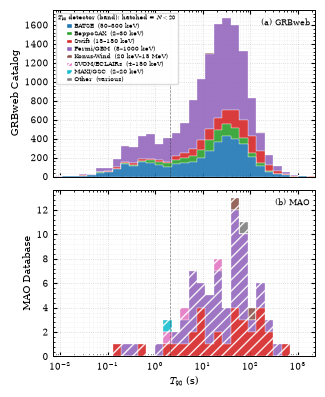

In [73]:
plt.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "cm",
    "axes.linewidth": 0.7,
    "axes.labelsize": 7.5,
    "axes.labelweight": "light",
    "xtick.labelsize": 6.5,
    "ytick.labelsize": 6.5,
    "legend.fontsize": 5.0,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    "xtick.major.size": 3.0,
    "ytick.major.size": 3.0,
    "xtick.minor.size": 1.5,
    "ytick.minor.size": 1.5,
    "savefig.dpi": 600,
})

DETECTORS = {
    "BATSE":        {"color": "#1f77b4", "band": "50–300 keV"},
    "BeppoSAX":     {"color": "#2ca02c", "band": "2–30 keV"},
    "Swift":        {"color": "#d62728", "band": "15–150 keV"},
    "Fermi/GBM":    {"color": "#9467bd", "band": "8–1000 keV"},
    "Konus-Wind":   {"color": "#8c564b", "band": "20 keV–15 MeV"},
    "SVOM/ECLAIRs": {"color": "#e377c2", "band": "4–150 keV"},
    "MAXI/GSC":     {"color": "#17becf", "band": "2–20 keV"},
    "Other":        {"color": "#7f7f7f", "band": "various"},
}
SMALL_N_THRESHOLD = 20

def apply_hatch(patch_containers, hatches):
    def iter_patches(obj):
        if isinstance(obj, mpatches.Patch):
            yield obj
        elif isinstance(obj, (list, tuple, np.ndarray)):
            for x in obj:
                yield from iter_patches(x)

    for container, hatch in zip(patch_containers, hatches):
        if not hatch:
            continue
        for p in iter_patches(container):
            p.set_hatch(hatch)
            p.set_edgecolor("white")
            p.set_linewidth(0.25)

mao = pd.read_csv("maogrb_updated_2026.csv")
mao.columns = mao.columns.str.strip()
mao = mao[mao["GRB_name"].notna()].copy()
mao["GRB_name"] = mao["GRB_name"].astype(str).str.strip()
mao["t90"] = pd.to_numeric(mao["t90"], errors="coerce")
mao["GRB_trigger_source"] = mao["GRB_trigger_source"].astype(str).str.strip()

def norm_mao_det(s):
    s = str(s)
    if "Fermi" in s: return "Fermi/GBM"
    if "Swift" in s: return "Swift"
    if "SVOM"  in s: return "SVOM/ECLAIRs"
    if "Konus" in s: return "Konus-Wind"
    if "MAXI"  in s: return "MAXI/GSC"
    return "Other"

mao["detector"] = mao["GRB_trigger_source"].apply(norm_mao_det)

conn = sqlite3.connect("GRBweb2.sqlite")

def read_t90(table, name_col, t90_col="T90", detector=None):
    q = f"""
        SELECT {name_col} AS GRB_name, {t90_col} AS T90_raw
        FROM {table}
        WHERE {t90_col} IS NOT NULL AND {t90_col} > 0
    """
    df = pd.read_sql_query(q, conn)
    df["GRB_name"] = df["GRB_name"].astype(str).str.strip()
    if detector is not None:
        df["detector"] = detector
    return df

batse    = read_t90("BATSE",     "GRB_name",       "T90", "BATSE")
bepposax = read_t90("BeppoSAX",  "GRB_name",       "T90", "BeppoSAX")
swift    = read_t90("Swift",     "GRB_name",       "T90", "Swift")
gbm      = read_t90("Fermi_GBM", "GRB_name_Fermi", "T90", "Fermi/GBM")

summary = pd.read_sql_query(
    "SELECT GRB_name, T90, T90_source FROM Summary "
    "WHERE T90 IS NOT NULL AND T90 > 0", conn
)
summary["GRB_name"] = summary["GRB_name"].astype(str).str.strip()

def source_to_detector(src):
    s = str(src)
    if "Konus"     in s: return "Konus-Wind"
    if "SVOM"      in s: return "SVOM/ECLAIRs"
    if "ECLAIR"    in s: return "SVOM/ECLAIRs"
    if "Swift"     in s: return "Swift"
    if "Fermi_GBM" in s: return "Fermi/GBM"
    if "BATSE"     in s: return "BATSE"
    if "BeppoSAX"  in s: return "BeppoSAX"
    return "Other"

summary["detector"] = summary["T90_source"].apply(source_to_detector)
summary = summary.rename(columns={"T90": "T90_raw"})

covered = set(batse.GRB_name) | set(bepposax.GRB_name) \
        | set(swift.GRB_name) | set(gbm.GRB_name)
summary_only = summary[~summary["GRB_name"].isin(covered)].copy()

conn.close()

global_df = pd.concat(
    [batse, bepposax, swift, gbm, summary_only], ignore_index=True
)
global_df["T90"] = pd.to_numeric(global_df["T90_raw"], errors="coerce")
global_df = global_df.dropna(subset=["T90"])
global_df = global_df[global_df["T90"] > 0]

if (global_df["detector"] == "SVOM/ECLAIRs").sum() == 0:
    svom_from_mao = mao.loc[
        mao["detector"] == "SVOM/ECLAIRs", ["GRB_name", "t90"]
    ].copy().rename(columns={"t90": "T90_raw"})
    svom_from_mao["detector"] = "SVOM/ECLAIRs"
    global_df = pd.concat([global_df, svom_from_mao], ignore_index=True)
    global_df["T90"] = pd.to_numeric(global_df["T90_raw"], errors="coerce")
    global_df = global_df.dropna(subset=["T90"])
    global_df = global_df[global_df["T90"] > 0]
    print(">> Added SVOM/ECLAIRs from MAO sample (GRBweb lacked them).")

print("=" * 60)
print("GLOBAL CATALOG — DETECTOR BREAKDOWN")
print("=" * 60)
print(global_df["detector"].value_counts().to_string())
print("\n" + "=" * 60)
print("MAO SAMPLE — DETECTOR BREAKDOWN")
print("=" * 60)
print(mao["detector"].value_counts().to_string())

all_t90 = np.concatenate([
    global_df["T90"].values,
    mao["t90"].dropna().values,
])
all_t90 = all_t90[all_t90 > 0]

bins = np.logspace(np.log10(all_t90.min() * 0.9),
                   np.log10(all_t90.max() * 1.1), 32)

fig, (ax_top, ax_bot) = plt.subplots(
    2, 1, figsize=(3.38, 4.5), sharex=True,
    gridspec_kw={"hspace": 0.08}
)

det_order_global = ["BATSE", "BeppoSAX", "Swift", "Fermi/GBM",
                    "Konus-Wind", "SVOM/ECLAIRs", "MAXI/GSC", "Other"]
det_order_mao    = ["Swift", "Fermi/GBM", "SVOM/ECLAIRs",
                    "Konus-Wind", "MAXI/GSC", "Other"]

data_top   = [global_df.loc[global_df["detector"] == d, "T90"].values
              for d in det_order_global]
colors_top = [DETECTORS[d]["color"] for d in det_order_global]
hatches_top = ["///" if len(arr) < SMALL_N_THRESHOLD else None
               for arr in data_top]

bars_top = ax_top.hist(
    data_top, bins=bins, stacked=True,
    histtype="stepfilled",
    color=colors_top, edgecolor="white", linewidth=0.25, alpha=0.9,
)
apply_hatch(bars_top, hatches_top)
ax_top.set_ylabel("GRBweb Catalog", labelpad=3,
                  fontweight="light", fontsize=7.0)

data_bot   = [mao.loc[mao["detector"] == d, "t90"].dropna().values
              for d in det_order_mao]
colors_bot = [DETECTORS[d]["color"] for d in det_order_mao]
hatches_bot = ["///" if len(arr) < SMALL_N_THRESHOLD else None
               for arr in data_bot]

bars_bot = ax_bot.hist(
    data_bot, bins=bins, stacked=True,
    histtype="stepfilled",
    color=colors_bot, edgecolor="white", linewidth=0.25, alpha=0.9,
)
apply_hatch(bars_bot, hatches_bot)
ax_bot.set_ylabel("MAO Database", labelpad=3,
                  fontweight="light", fontsize=7.0)
ax_bot.set_xlabel(r"$T_{90}$ (s)", labelpad=3,
                  fontweight="light", fontsize=7.0)

for ax in (ax_top, ax_bot):
    ax.set_xscale("log")
    ax.axvline(2, linestyle="--", linewidth=0.5,
               color="#333333", alpha=0.6, zorder=5)
    ax.yaxis.set_minor_locator(AutoMinorLocator(5))
    ax.set_axisbelow(True)
    ax.grid(True, which="major", linestyle=":", linewidth=0.6,
            alpha=0.35, color="gray")
    ax.grid(True, which="minor", linestyle=":", linewidth=0.4,
            alpha=0.20, color="gray")

ax_bot.set_xlim(bins[0], bins[-1])

legend_handles = [
    Patch(facecolor=DETECTORS[d]["color"], edgecolor="white",
          hatch=("///" if len(global_df.loc[global_df["detector"] == d]) < SMALL_N_THRESHOLD else None),
          label=f"{d}  ({DETECTORS[d]['band']})")
    for d in det_order_global
]
ax_top.legend(
    handles=legend_handles,
    loc="upper left",
    frameon=True, facecolor="white",
    edgecolor="0.85", framealpha=0.95,
    fontsize=4.5, handlelength=0.9,
    borderpad=0.25, labelspacing=0.18,
    handletextpad=0.35,
    title=r"$T_{90}$ detector (band); hatched = $N<20$",
    title_fontsize=4.5,
)

ax_top.text(0.98, 0.95, "(a) GRBweb",
            transform=ax_top.transAxes,
            ha="right", va="top", fontsize=6)
ax_bot.text(0.98, 0.95, "(b) MAO",
            transform=ax_bot.transAxes,
            ha="right", va="top", fontsize=6)

plt.tight_layout(pad=0.3)

for ext in ("pdf", "png", "eps"):
    plt.savefig(f"plot1.{ext}",
                bbox_inches="tight", dpi=600, format=ext)

plt.show()

Let's plot the saosonal efficiency 

/var/folders/q7/mbq39cqx4j100pvwhrk5n5tw0000gn/T/ipykernel_89526/1222884027.py:302: UserWarning: AutoMinorLocator does not work on logarithmic scales
  plt.tight_layout(pad=0.3)
/var/folders/q7/mbq39cqx4j100pvwhrk5n5tw0000gn/T/ipykernel_89526/1222884027.py:365: UserWarning: AutoMinorLocator does not work on logarithmic scales
  fig.savefig(
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very l

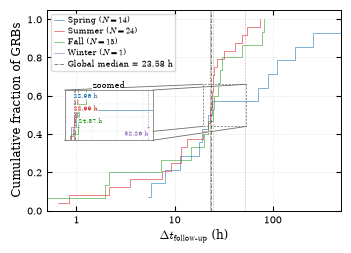

In [79]:
from matplotlib.ticker import (
    AutoMinorLocator,
    FixedLocator,
    FixedFormatter,
    MaxNLocator,
)

plt.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "cm",
    "axes.linewidth": 0.7,
    "axes.labelsize": 8.5,
    "axes.labelweight": "light",
    "xtick.labelsize": 7.5,
    "ytick.labelsize": 7.5,
    "legend.fontsize": 6.0,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    "xtick.major.size": 3.5,
    "ytick.major.size": 3.5,
    "xtick.minor.size": 1.8,
    "ytick.minor.size": 1.8,
    "savefig.dpi": 600,
})

season_colors = {
    "Spring": "#1f77b4",
    "Summer": "#d62728",
    "Fall":   "#2ca02c",
    "Winter": "#9467bd",
}

season_order = ["Spring", "Summer", "Fall", "Winter"]

df_box = pd.read_csv("mao_grb_list_edited_updated_2026.csv")
df_box.columns = df_box.columns.str.strip()
df_box["GRB_name"] = df_box["GRB_name"].astype(str).str.strip()

df_box["to_dt"] = pd.to_datetime(
    df_box["to_time"],
    format="mixed",
    dayfirst=True,
    errors="coerce",
)

df_box["obs_dt"] = pd.to_datetime(
    df_box["date-obs"],
    format="mixed",
    dayfirst=True,
    errors="coerce",
)

df_box["delay_hours"] = (
    df_box["obs_dt"] - df_box["to_dt"]
).dt.total_seconds() / 3600.0

df_box["date-obs"] = df_box["obs_dt"]

df_box = df_box.dropna(subset=["delay_hours", "date-obs"])
df_box = df_box[df_box["delay_hours"] > 0].copy()

def get_season(month):
    if month in [3, 4, 5]:
        return "Spring"
    if month in [6, 7, 8]:
        return "Summer"
    if month in [9, 10, 11]:
        return "Fall"
    return "Winter"

df_box["Season"] = df_box["date-obs"].dt.month.map(get_season)
global_median = df_box["delay_hours"].median()

season_data = {}
season_medians = {}

for s in season_order:
    d = np.sort(
        df_box.loc[df_box["Season"] == s, "delay_hours"].values
    )
    if len(d) > 0:
        season_data[s] = d
        season_medians[s] = np.median(d)

fig, ax = plt.subplots(figsize=(3.38, 2.4))

for s in season_order:
    if s not in season_data:
        continue

    d = season_data[s]
    y = np.arange(1, len(d) + 1) / len(d)

    ax.step(
        d, y,
        where="post",
        color=season_colors[s],
        linewidth=0.4,
        label=f"{s} ($N={len(d)}$)",
    )

    ax.axvline(
        season_medians[s],
        color=season_colors[s],
        linestyle="--",
        linewidth=0.4,
        alpha=0.55,
        zorder=2,
    )

ax.axvline(
    global_median,
    color="#222222",
    linestyle="-.",
    linewidth=0.4,
    zorder=3,
    label=f"Global median = {global_median:.2f} h",
)

ax.set_xscale("log")
ax.set_xlim(0.5, 500)
ax.set_ylim(0, 1.05)

ax.set_xlabel(
    r"$\Delta t_{\mathrm{follow\text{-}up}}$ (h)",
    labelpad=3,
)
ax.set_ylabel("Cumulative fraction of GRBs", labelpad=3)

ticks = [1, 10, 100]
ax.xaxis.set_major_locator(FixedLocator(ticks))
ax.xaxis.set_major_formatter(
    FixedFormatter([f"{t:g}" for t in ticks])
)
ax.xaxis.set_minor_locator(AutoMinorLocator(9))

ax.set_axisbelow(True)

ax.grid(
    True, which="major",
    linestyle=":", linewidth=0.4,
    alpha=0.4, color="gray",
)
ax.grid(
    True, which="minor",
    linestyle=":", linewidth=0.3,
    alpha=0.2, color="gray",
)

leg = ax.legend(
    loc="upper left",
    frameon=True,
    facecolor="white",
    edgecolor="0.85",
    framealpha=0.95,
    fontsize=6.0,
    handlelength=1.3,
    borderpad=0.3,
    labelspacing=0.22,
    handletextpad=0.4,
)

meds_arr = np.array(
    list(season_medians.values()) + [global_median]
)

spread = np.ptp(meds_arr)
padding = max(
    0.06 * spread,
    0.015 * global_median,
    1e-6,
)

zoom_xmin = max(0, meds_arr.min() - 2 * padding)
zoom_xmax = meds_arr.max() + padding

ax_ins = ax.inset_axes([0.06, 0.35, 0.30, 0.25])
ax_ins.set_facecolor("white")

for s in season_order:
    if s not in season_data:
        continue

    d = season_data[s]
    y = np.arange(1, len(d) + 1) / len(d)
    med = season_medians[s]

    ax_ins.step(
        d, y,
        where="post",
        color=season_colors[s],
        linewidth=0.4,
    )

    ax_ins.axvline(
        med,
        color=season_colors[s],
        linestyle="--",
        linewidth=0.4,
        alpha=0.75,
    )

    ax_ins.scatter(
        med, 0.5,
        s=3,
        facecolor=season_colors[s],
        edgecolor="white",
        linewidth=0.4,
        zorder=6,
    )

ax_ins.axvline(
    global_median,
    color="#222222",
    linestyle="-.",
    linewidth=0.4,
    zorder=3,
)

ax_ins.set_xlim(zoom_xmin, zoom_xmax)

ax_ins.set_yticks([0.45, 0.50, 0.60])
ax_ins.set_ylim(0.44, 0.66)

ordered = sorted(
    season_medians.items(),
    key=lambda item: item[1],
)

label_heights = [0.88, 0.63, 0.38, 0.13]

for (s, med), height in zip(ordered, label_heights):
    x_fraction = (
        (med - zoom_xmin) / (zoom_xmax - zoom_xmin)
    )

    if x_fraction < 0.30:
        alignment = "left"
    elif x_fraction > 0.70:
        alignment = "right"
    else:
        alignment = "center"

    ax_ins.text(
        med,
        height,
        f"{med:.2f} h",
        transform=ax_ins.get_xaxis_transform(),
        color=season_colors[s],
        fontsize=4.0,
        ha=alignment,
        va="center",
        zorder=7,
        bbox=dict(
            facecolor="white",
            edgecolor="none",
            boxstyle="round,pad=0.05",
            alpha=0.95,
        ),
    )

ax_ins.xaxis.set_major_locator(
    MaxNLocator(nbins=2, min_n_ticks=2)
)
ax_ins.ticklabel_format(
    axis="x",
    style="plain",
    useOffset=False,
)

ax_ins.tick_params(
    axis="both",
    labelsize=5.0,
    pad=1,
)

ax_ins.set_axisbelow(True)
ax_ins.grid(
    True,
    which="major",
    linestyle=":",
    linewidth=0.4,
    alpha=0.2,
    color="gray",
)

ax_ins.set_title("zoomed", fontsize=5.6, pad=1.5)

ax_ins.set_xticks([])
ax_ins.set_yticks([])
ax_ins.tick_params(which="both", length=0)
ax_ins.grid(False, which="both")

import matplotlib.patheffects as pe

plt.tight_layout(pad=0.3)

indicator = ax.indicate_inset_zoom(
    ax_ins,
    edgecolor="0.40",
    linewidth=0.60,
    alpha=1.0,
    zorder=2,
)

if hasattr(indicator, "connectors"):
    zoom_box = indicator.rectangle
    connectors = indicator.connectors
else:
    zoom_box, connectors = indicator

zoom_box.set_facecolor("none")
zoom_box.set_linestyle((0, (3, 2)))

for connector in connectors:
    connector.set_visible(True)
    connector.set_linestyle("-")
    connector.set_linewidth(0.60)
    connector.set_edgecolor("0.42")

    connector.set_path_effects([
        pe.Stroke(linewidth=1.3, foreground="white"),
        pe.Normal(),
    ])

ax_ins.title.set_bbox(
    dict(facecolor="white", edgecolor="none", pad=0.3)
)

from matplotlib.ticker import MaxNLocator

for spine in ax_ins.spines.values():
    spine.set_color("0.40")
    spine.set_linewidth(0.5)

zoom_box.set_edgecolor("0.40")
zoom_box.set_linewidth(0.5)

ax_ins.xaxis.set_major_locator(MaxNLocator(nbins=4))
ax_ins.yaxis.set_major_locator(MaxNLocator(nbins=4))

ax_ins.tick_params(
    axis="both", which="both",
    bottom=False, top=False, left=False, right=False,
    labelbottom=False, labeltop=False,
    labelleft=False, labelright=False,
)

ax_ins.set_axisbelow(True)
ax_ins.grid(
    True, which="major",
    color="0.80",
    linestyle=":",
    linewidth=0.33,
    alpha=1.0,
)
for ext in ("pdf", "png", "eps"):
    
    fig.savefig(
        f"plot3.{ext}",
        bbox_inches="tight",
        dpi=600,
        format=ext,
    )

plt.show()

Summary stats

In [83]:
MAO_FILE = "maogrb_updated_2026.csv"
FOLLOWUP_FILE = "mao_grb_list_edited_updated_2026.csv"
DB_FILE = "GRBweb2.sqlite"

detectors = [
    "Fermi", "BATSE", "Swift", "BeppoSAX",
    "Konus", "SVOM", "MAXI", "Other",
]
seasons = ["Spring", "Summer", "Fall", "Winter"]

def name_key(values):
    return (
        values.astype("string")
        .str.upper()
        .str.replace(r"\s+", "", regex=True)
        .str.replace(r"^(GRB|BN)", "", regex=True)
        .replace("", pd.NA)
    )

def detector_name(value):
    text = "".join(c for c in str(value).upper() if c.isalnum())

    if text == "FERMI":
        return "Fermi"

    for token, label in [
        ("BATSE", "BATSE"),
        ("BEPPO", "BeppoSAX"),
        ("SWIFT", "Swift"),
        ("FERMIGBM", "Fermi"),
        ("KONUS", "Konus"),
        ("SVOM", "SVOM"),
        ("ECLAIR", "SVOM"),
        ("MAXI", "MAXI"),
    ]:
        if token in text:
            return label

    return "Other"

database = Path(DB_FILE)

if not database.is_file():
    raise FileNotFoundError(DB_FILE)

with sqlite3.connect(
    database.resolve().as_uri() + "?mode=ro", uri=True
) as con:

    summary = pd.read_sql_query(
        """
        SELECT GRB_name, GRB_name_Fermi, T90, T90_source
        FROM Summary
        """,
        con,
    )

    parts = []

    for table, name_column, detector in [
        ("BATSE", "GRB_name", "BATSE"),
        ("BeppoSAX", "GRB_name", "BeppoSAX"),
        ("Swift", "GRB_name", "Swift"),
        ("Fermi_GBM", "GRB_name_Fermi", "Fermi"),
    ]:
        part = pd.read_sql_query(
            f'SELECT "{name_column}" AS GRB_name, T90 FROM "{table}"',
            con,
        )
        part["Detector"] = detector
        parts.append(part)

aliases = pd.DataFrame({
    "fermi_key": name_key(summary["GRB_name_Fermi"]),
    "key": name_key(summary["GRB_name"]),
}).dropna().drop_duplicates()

if aliases["fermi_key"].duplicated().any():
    raise ValueError(
        "Some Fermi identifiers match multiple GRBs; inspect aliases."
    )

fermi_aliases = aliases.set_index("fermi_key")["key"]

summary["Detector"] = summary["T90_source"].map(detector_name)

catalogue = pd.concat(
    [
        p[["GRB_name", "T90", "Detector"]]
        for p in parts + [summary]
        if not p.empty
    ],
    ignore_index=True,
)

catalogue["T90"] = pd.to_numeric(
    catalogue["T90"], errors="coerce"
)
catalogue["key"] = name_key(catalogue["GRB_name"])
catalogue["key"] = (
    catalogue["key"].map(fermi_aliases)
    .fillna(catalogue["key"])
)

catalogue = catalogue.loc[
    catalogue["key"].notna()
    & np.isfinite(catalogue["T90"])
    & catalogue["T90"].gt(0)
].drop_duplicates(["key", "Detector"])

grbweb_counts = (
    catalogue.groupby("Detector")["key"]
    .nunique()
    .reindex(detectors, fill_value=0)
    .rename("GRBweb")
)

mao = pd.read_csv(MAO_FILE, dtype="string")
followup = pd.read_csv(FOLLOWUP_FILE, dtype="string")

for frame in (mao, followup):
    frame.columns = frame.columns.str.strip()
    frame["key"] = name_key(frame["GRB_name"])

mao["t90"] = pd.to_numeric(mao["t90"], errors="coerce")
mao = mao.loc[mao["key"].notna()].copy()

for column, destination in [
    ("to_time", "trigger_dt"),
    ("date-obs", "obs_dt"),
]:
    followup[destination] = pd.to_datetime(
        followup[column],
        format="mixed",
        dayfirst=True,
        utc=True,
        errors="coerce",
    )

followup["delay_hours"] = (
    followup["obs_dt"] - followup["trigger_dt"]
).dt.total_seconds() / 3600.0

valid = (
    followup["key"].notna()
    & np.isfinite(followup["delay_hours"])
    & followup["delay_hours"].gt(0)
)

print("Excluded invalid follow-up rows:", int((~valid).sum()))
followup = followup.loc[valid].copy()

if followup.empty:
    raise ValueError("No valid positive follow-up delays.")

followup["Season"] = followup["obs_dt"].dt.month.map(
    lambda month: ["Winter", "Spring", "Summer", "Fall"][
        (month % 12) // 3
    ]
)

sample = followup.merge(
    mao[["key", "t90", "GRB_trigger_source"]],
    on="key",
    how="left",
    validate="one_to_one",
)

sample["Detector"] = sample["GRB_trigger_source"].map(detector_name)

has_t90 = (
    np.isfinite(sample["t90"]) & sample["t90"].gt(0)
).fillna(False)

t90_sample = sample.loc[has_t90].copy()

mao_counts = (
    t90_sample.groupby(["Detector", "Season"])["key"]
    .nunique()
    .unstack(fill_value=0)
    .reindex(index=detectors, columns=seasons, fill_value=0)
)

table = pd.concat([grbweb_counts, mao_counts], axis=1)
table["MAO total"] = mao_counts.sum(axis=1)

table.loc["Unique total", "GRBweb"] = catalogue["key"].nunique()
table.loc["Unique total", seasons] = mao_counts.sum(axis=0)
table.loc["Unique total", "MAO total"] = t90_sample["key"].nunique()

print("\nDETECTOR COUNTS — VALID T90")
display(table.astype(int))

print("GRBweb detector rows can overlap; its unique total is not their sum.")
print("MAO detector labels use GRB_trigger_source, as in your T90 plot.")

delays = sample["delay_hours"]

delay_statistics = pd.DataFrame({
    "Value": {
        "Number of GRBs": str(len(delays)),
        "Median": f"{delays.median():.2f} h",
        "<24 h": f"{100 * delays.lt(24).mean():.1f}%",
        "<100 h": f"{100 * delays.lt(100).mean():.1f}%",
        "Shortest": f"{delays.min():.2f} h",
        "Longest": f"{delays.max():.1f} h",
    }
})

print("\nFOLLOW-UP DELAY STATISTICS")
display(delay_statistics)

print(
    f"\nFollow-up sample: {len(sample)} GRBs"
    f"\nWith valid T90: {len(t90_sample)} GRBs"
)

if (~has_t90).any():
    print("\nGRBs missing a valid T90:")
    display(
        sample.loc[
            ~has_t90,
            ["GRB_name", "t90", "GRB_trigger_source"],
        ]
    )

Excluded invalid follow-up rows: 0

DETECTOR COUNTS — VALID T90


,GRBweb,Spring,Summer,Fall,Winter,MAO total
Detector,,,,,,
Fermi,4409,8,10,5,1,24
BATSE,3805,0,0,0,0,0
Swift,1635,4,4,4,0,12
BeppoSAX,1003,0,0,0,0,0
Konus,7,0,0,0,0,0
SVOM,0,0,1,2,0,3
MAXI,0,0,1,0,0,1
Other,13,0,0,0,0,0
Unique total,10007,12,16,11,1,40


GRBweb detector rows can overlap; its unique total is not their sum.
MAO detector labels use GRB_trigger_source, as in your T90 plot.

FOLLOW-UP DELAY STATISTICS


,Value
Number of GRBs,54
Median,23.58 h
<24 h,50.0%
<100 h,92.6%
Shortest,0.20 h
Longest,630.5 h



Follow-up sample: 54 GRBs
With valid T90: 40 GRBs

GRBs missing a valid T90:


,GRB_name,t90,GRB_trigger_source
6,GRB230618A,<NA>,Fermi/GBM
12,GRB240805B,<NA>,Swift/BAT
18,GRB250317B,<NA>,SVOM/ECLAIRs
20,GRB250419A,<NA>,SVOM/ECLAIRs
24,GRB250610B,<NA>,SVOM/ECLAIRs
25,GRB250615A,<NA>,Swift/BAT
29,GRB250706A,<NA>,Swift/BAT
36,GRB250924A,<NA>,Swift/BAT
37,GRB250925A,<NA>,Swift/BAT
40,GRB251007A,<NA>,Swift/BAT
